# Part 4 Recap: Pip's café meets data science ☕🐍📊

**Part 4 - Data Science and AI** (Lectures 9-10). The summary of everything we learned in Part 4, and the end of the course journey.

Pip's café now has a whole week of orders. Writing a loop for every question is slow, so Pip borrows the tools that scientists use:
NumPy for fast math, Pandas for tables, Matplotlib for charts and scikit-learn for a first taste of machine learning.

| Lecture | Big idea | In the café |
|---|---|---|
| L09 NumPy & Pandas | `import`, arrays, math on a whole array, filters, statistics, 2-D arrays, an image is numbers, DataFrames and CSV | Prices, the weekly sales table, the orders table |
| L10 Plots, ML & Wrap-up | line, bar, scatter, histogram; regression, classification, clustering; objects and methods; the final project | Charts of the week, predicting sales, groups of customers |

**How to use:** run each cell with **Shift+Enter** (from the top: later cells need the earlier ones). **Predict** before you run.
At the end: a mini final project, a Bug Zoo, a quiz, a cheat sheet and a look back at the whole course.

## 1. Borrowing tools: import (Lecture 9)

**Reminder**
* `import numpy as np` opens a toolbox and gives it a short nickname. After that: `np.something`.
* Python comes with many toolboxes, and Colab already has the big ones installed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(np.sqrt(16), np.pi)

4.0 3.141592653589793


## 2. Math on everything at once: NumPy arrays (Lecture 9)

**Reminder**
* `np.array([...])` is like a list, but math works on **every item at once**.
* A list `* 2` repeats the list. An array `* 2` doubles every number.
* `prices > 10` gives an array of `True` / `False`. `prices[prices > 10]` keeps only the `True` ones.
* Statistics in one word: `np.mean`, `np.median`, `np.percentile`, `np.max`.

In [2]:
menu_items = ["Coffee", "Tea", "Croissant", "Cookie", "Muffin"]
price_list = [12.5, 8, 9, 4, 11]
prices = np.array(price_list)

print(price_list * 2)   # list: repeated
print(prices * 2)       # array: every price doubled

[12.5, 8, 9, 4, 11, 12.5, 8, 9, 4, 11]
[25. 16. 18.  8. 22.]


**Add 18% VAT.** In Part 2 this needed a loop. Now it is one line:

In [3]:
with_vat = prices * 1.18
print(with_vat)
print("Over 10 ILS?", prices > 10)
print("Only those:", prices[prices > 10])

[14.75  9.44 10.62  4.72 12.98]
Over 10 ILS? [ True False False False  True]
Only those: [12.5 11. ]


**Refactor moment.** In Part 3 we wrote `median()` by hand: sort, find the middle, handle even and odd. NumPy does it in one word,
and gives the **same** answer on Friday's orders:

In [4]:
friday = np.array([21.5, 9, 37.5, 12.5, 450, 8, 25])

print("Mean:  ", np.mean(friday))
print("Median:", np.median(friday))        # Part 3 by hand: 21.5
print(f"90th percentile: {np.percentile(friday, 90):.1f}")

Mean:   80.5
Median: 21.5
90th percentile: 202.5


## 3. Tables of numbers: 2-D arrays (Lecture 9)

**Reminder**
* A 2-D array has rows and columns. `.shape` gives (rows, columns). `table[row, col]` picks one cell.
* `axis=0` works **down** each column, `axis=1` works **across** each row.

Cups sold this week, one row per drink, one column per day (Sun-Thu):

In [5]:
cups = np.array([
    [42, 38, 51, 47, 60],   # Coffee
    [20, 25, 18, 30, 22],   # Tea
    [15, 12, 20, 18, 25],   # Iced coffee
])

print("Shape:", cups.shape)
print("Tea on Tuesday:", cups[1, 2])
print("Per day (axis=0):  ", cups.sum(axis=0))
print("Per drink (axis=1):", cups.sum(axis=1))
print("Average per drink: ", cups.mean(axis=1))

Shape: (3, 5)
Tea on Tuesday: 18
Per day (axis=0):   [ 77  75  89  95 107]
Per drink (axis=1): [238 115  90]
Average per drink:  [47.6 23.  18. ]


## 4. An image is just numbers (Lecture 9)

**Reminder**
* A picture is a 2-D array of numbers: one number per pixel (3 numbers for color: red, green, blue).
* Filters are math on the array: `255 - image` inverts, `image[::-1]` flips, slicing crops.

Pip's logo, 8 x 8 pixels: 0 = background, 1 = cup, 2 = coffee.

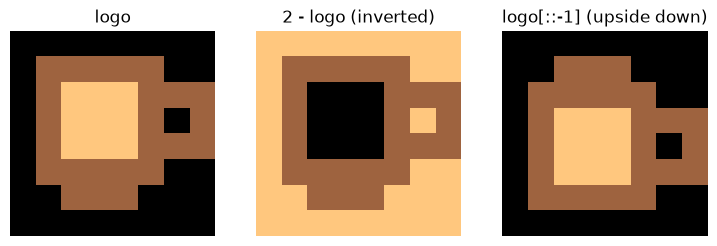

In [6]:
logo = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0, 0],
    [0, 1, 2, 2, 2, 1, 1, 1],
    [0, 1, 2, 2, 2, 1, 0, 1],
    [0, 1, 2, 2, 2, 1, 1, 1],
    [0, 1, 1, 1, 1, 1, 0, 0],
    [0, 0, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
])

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(logo, cmap="copper")
axes[0].set_title("logo")
axes[1].imshow(2 - logo, cmap="copper")
axes[1].set_title("2 - logo (inverted)")
axes[2].imshow(logo[::-1], cmap="copper")
axes[2].set_title("logo[::-1] (upside down)")
for ax in axes:
    ax.axis("off")
plt.show()

(`plt.subplots` puts several pictures side by side: you don't need to know it, just run it.)

## 5. The orders table: Pandas (Lecture 9)

**Reminder**
* A **DataFrame** is a table with named columns. One column (`df["price"]`) works like an array.
* Real data lives in CSV files: `df = pd.read_csv("coffee_orders.csv")`.
* `head()` shows the first rows, `describe()` a summary, `value_counts()` counts each value.
* Filter rows: `df[df["drink"] == "Latte"]`.

Pip's first week. With a real file you would write `pd.read_csv("pip_week.csv")`. Here we build the same table from a dictionary,
so the notebook works without uploading anything. (All data is made up.)

In [7]:
week = {
    "day":    ["Sun", "Sun", "Sun", "Sun", "Mon", "Mon", "Mon", "Tue", "Tue", "Tue", "Tue", "Tue",
               "Wed", "Wed", "Wed", "Thu", "Thu", "Thu", "Thu", "Thu", "Thu"],
    "drink":  ["Latte", "Tea", "Espresso", "Latte", "Iced coffee", "Latte", "Tea", "Latte", "Mocha", "Iced coffee",
               "Tea", "Latte", "Espresso", "Latte", "Iced coffee", "Latte", "Mocha", "Iced coffee", "Iced coffee", "Tea", "Latte"],
    "size":   ["M", "S", "S", "L", "L", "M", "M", "S", "L", "M", "S", "L", "S", "M", "L", "M", "M", "L", "M", "S", "L"],
    "price":  [15, 9, 9, 18, 19, 15, 10, 13, 20, 16, 9, 18, 9, 15, 19, 15, 17, 19, 16, 9, 18],
    "rating": [5, 4, 5, 4, 5, 3, 4, 5, 5, 4, 3, 5, 4, 4, 5, 5, 4, 5, 4, 3, 5],
}
df = pd.DataFrame(week)
df.head()

,day,drink,size,price,rating
0,Sun,Latte,M,15,5
1,Sun,Tea,S,9,4
2,Sun,Espresso,S,9,5
3,Sun,Latte,L,18,4
4,Mon,Iced coffee,L,19,5


In [8]:
print("Orders:", len(df))
print("Income:", df["price"].sum(), "ILS")
print("Average price:", round(df["price"].mean(), 2))
print("Median price: ", df["price"].median())

Orders: 21
Income: 308 ILS
Average price: 14.67
Median price:  15.0


(`round(x, 2)` keeps 2 digits after the point, like `:.2f` does in an f-string.)

**Questions in one line each:**

In [9]:
lattes = df[df["drink"] == "Latte"]
print("Lattes sold:", len(lattes))

expensive = df[df["price"] >= 18]
print("Orders of 18 ILS or more:", len(expensive))

print()
print(df["drink"].value_counts())

Lattes sold: 8
Orders of 18 ILS or more: 7

drink
Latte          8
Iced coffee    5
Tea            4
Espresso       2
Mocha          2
Name: count, dtype: int64


In [10]:
df.describe()

,price,rating
count,21.000000,21.000000
mean,14.666667,4.333333
std,3.953901,0.730297
min,9.000000,3.000000
25%,10.000000,4.000000
50%,15.000000,4.000000
75%,18.000000,5.000000
max,20.000000,5.000000


## 6. Charts (Lecture 10)

**Reminder**
* `plt.plot(x, y)` line, `plt.bar(x, y)` bars, `plt.scatter(x, y)` dots, `plt.hist(values)` histogram.
* **Always** add `plt.title`, `plt.xlabel`, `plt.ylabel`. Two lines? Add `label=` and `plt.legend()`.
* Finish with `plt.show()`.

**Line plot:** coffee and tea per day, from the 2-D array.

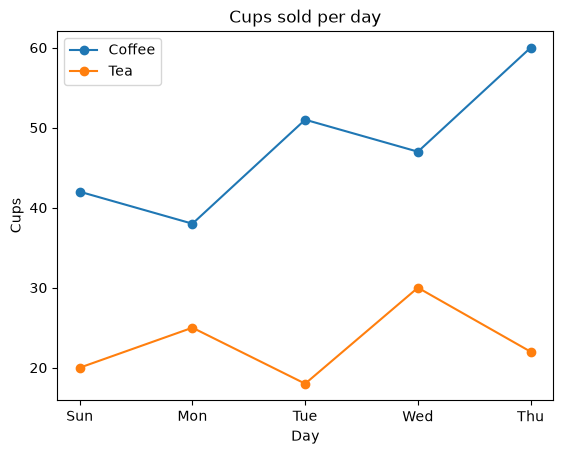

In [11]:
days = ["Sun", "Mon", "Tue", "Wed", "Thu"]

plt.plot(days, cups[0], marker="o", label="Coffee")
plt.plot(days, cups[1], marker="o", label="Tea")
plt.title("Cups sold per day")
plt.xlabel("Day")
plt.ylabel("Cups")
plt.legend()
plt.show()

**Bar chart:** the most popular drinks this week.

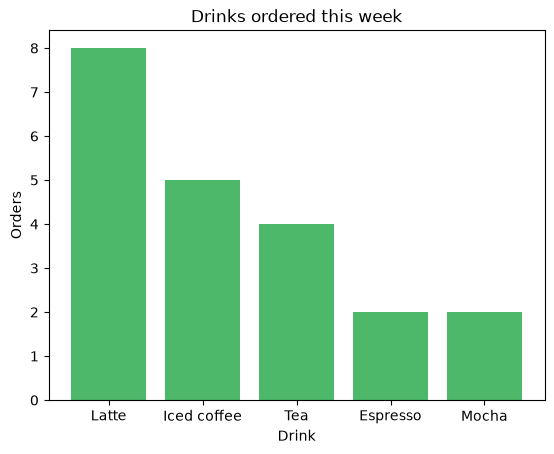

In [12]:
counts = df["drink"].value_counts()

plt.bar(counts.index, counts.values, color="#4DB86A")
plt.title("Drinks ordered this week")
plt.xlabel("Drink")
plt.ylabel("Orders")
plt.show()

**Scatter plot:** does the weather matter? Iced coffees sold on 12 days, against the temperature that day.

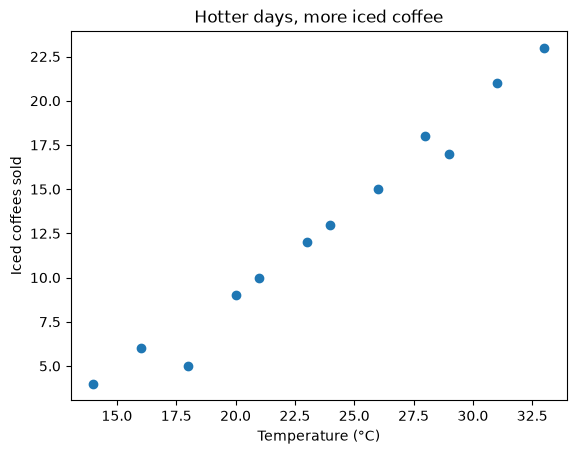

In [13]:
temperature = [14, 16, 18, 20, 21, 23, 24, 26, 28, 29, 31, 33]
iced_sold   = [ 4,  6,  5,  9, 10, 12, 13, 15, 18, 17, 21, 23]

plt.scatter(temperature, iced_sold)
plt.title("Hotter days, more iced coffee")
plt.xlabel("Temperature (°C)")
plt.ylabel("Iced coffees sold")
plt.show()

**Histogram:** how long do customers wait? 300 made-up waiting times, mostly around 4 minutes.

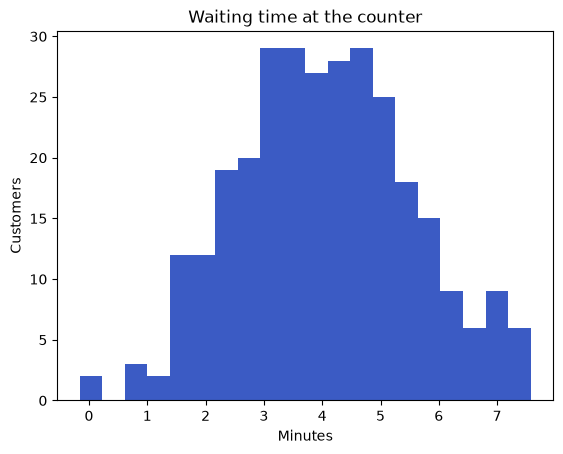

In [14]:
np.random.seed(0)
waits = np.random.normal(4, 1.5, 300)

plt.hist(waits, bins=20, color="#3B5BC4")
plt.title("Waiting time at the counter")
plt.xlabel("Minutes")
plt.ylabel("Customers")
plt.show()

## 7. A first taste of machine learning (Lecture 10)

**Reminder**
* **Regression** predicts a **number** (sales tomorrow). **Classification** predicts a **label** (hot or iced). **Clustering** finds **groups** by itself.
* scikit-learn always works the same way: make a model, `fit(X, y)` to learn, `predict(...)` to use it.
* `X` must be **2-D**: a list of rows, even with one feature: `[[14], [16], ...]`.
* A model knows only its data. It has **no common sense**.

**Regression:** predict iced coffee sales from the temperature.

In [15]:
from sklearn.linear_model import LinearRegression

X = []
for t in temperature:
    X.append([t])          # 2-D: one row per day

model = LinearRegression()
model.fit(X, iced_sold)

print(f"Prediction for 30°C: {model.predict([[30]])[0]:.1f} iced coffees")
print(f"Prediction for 60°C: {model.predict([[60]])[0]:.1f} iced coffees")

Prediction for 30°C: 19.3 iced coffees
Prediction for 60°C: 50.1 iced coffees


30°C: about 20 iced coffees, sounds right. 60°C: over 50 iced coffees... at 60°C nobody leaves the house!
The model only draws a line through its data. Outside that range it has **no common sense**.

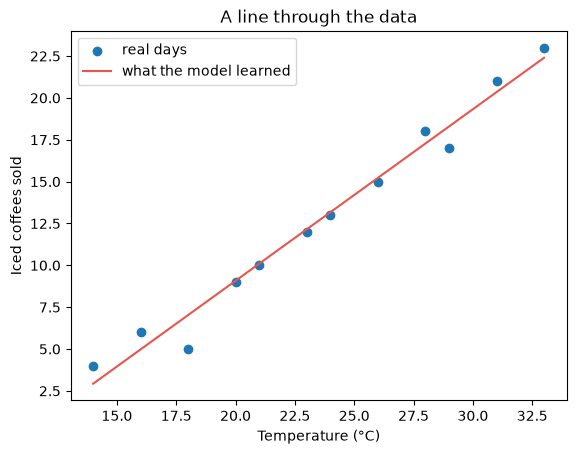

In [16]:
plt.scatter(temperature, iced_sold, label="real days")
plt.plot(temperature, model.predict(X), color="#E8554E", label="what the model learned")
plt.title("A line through the data")
plt.xlabel("Temperature (°C)")
plt.ylabel("Iced coffees sold")
plt.legend()
plt.show()

**Classification:** will the next customer order a hot or an iced drink? We know `[temperature, hour]` for 10 past orders.
`KNeighborsClassifier` looks at the 3 most similar past orders and takes the majority.

In [17]:
from sklearn.neighbors import KNeighborsClassifier

past = [[15, 8], [17, 9], [16, 14], [19, 10], [22, 16], [27, 13], [29, 15], [31, 12], [30, 17], [26, 14]]
kind = ["hot", "hot", "hot", "hot", "hot", "iced", "iced", "iced", "iced", "iced"]

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(past, kind)
print(knn.predict([[18, 9], [30, 14]]))

['hot' 'iced']


**Clustering:** what kinds of customers does Pip have? For 15 customers: visits per month and average spend. Nobody tells `KMeans` the groups. It finds them.

[1 1 1 1 1 0 0 0 0 0 2 2 2 2 2]


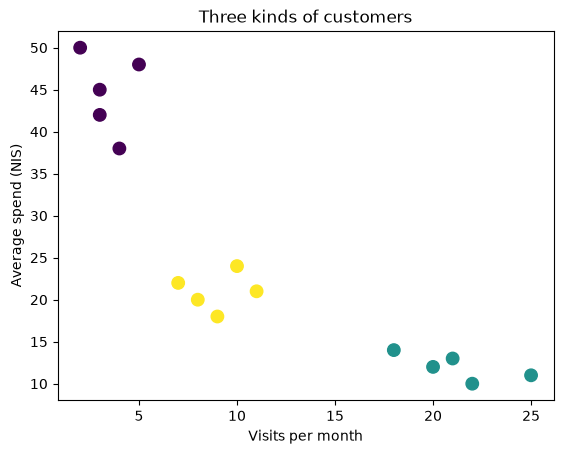

In [18]:
from sklearn.cluster import KMeans

customers = np.array([
    [20, 12], [22, 10], [18, 14], [25, 11], [21, 13],    # ?
    [3, 45],  [2, 50],  [4, 38],  [3, 42],  [5, 48],     # ?
    [8, 20],  [10, 24], [9, 18],  [7, 22],  [11, 21],    # ?
])

groups = KMeans(n_clusters=3, random_state=0).fit_predict(customers)
print(groups)

plt.scatter(customers[:, 0], customers[:, 1], c=groups, cmap="viridis", s=80)
plt.title("Three kinds of customers")
plt.xlabel("Visits per month")
plt.ylabel("Average spend (ILS)")
plt.show()

The model found: **regulars** (many visits, small orders), **party orders** (rare visits, big orders), and **in-between** customers.
The group numbers (0, 1, 2) are just names: the model doesn't know what they mean. **You** explain them.

## 8. A peek at objects: you've used them all along (Lecture 10)

**Reminder**
* An **object** is a value with its own abilities, called **methods**: `thing.method(...)`.
* Every value in Python is an object. You've been calling methods since Lecture 5.

In [19]:
basket = ["Tea"]
basket.append("Muffin")        # a list's method
print(basket)

name = "pip's café"
print(name.upper())            # a string's method

print(prices.mean())           # an array's method
print(df["price"].max())       # a column's method
print(type(model))             # our model is an object too: .fit() and .predict() are its methods

['Tea', 'Muffin']
PIP'S CAFÉ
8.9
20
<class 'sklearn.linear_model._base.LinearRegression'>


## 9. All together: a mini final project 🧾

The final project follows five steps. Here they are, on Pip's question.

**1. The question.** Pip wants to hire an extra barista for **one** day a week. Which day?

In [20]:
# 2. Load the data
#    (with a file: df = pd.read_csv("pip_week.csv"))
print(len(df), "orders")
df.head(3)

21 orders


,day,drink,size,price,rating
0,Sun,Latte,M,15,5
1,Sun,Tea,S,9,4
2,Sun,Espresso,S,9,5


In [21]:
# 3. Explore: income and number of orders per day (a loop + a filter, like in Lecture 10)
days = ["Sun", "Mon", "Tue", "Wed", "Thu"]
income = []
orders_per_day = []
for d in days:
    that_day = df[df["day"] == d]
    income.append(int(that_day["price"].sum()))
    orders_per_day.append(len(that_day))

print("Income:", income)
print("Orders:", orders_per_day)

Income: [51, 44, 76, 43, 94]
Orders: [4, 3, 5, 3, 6]


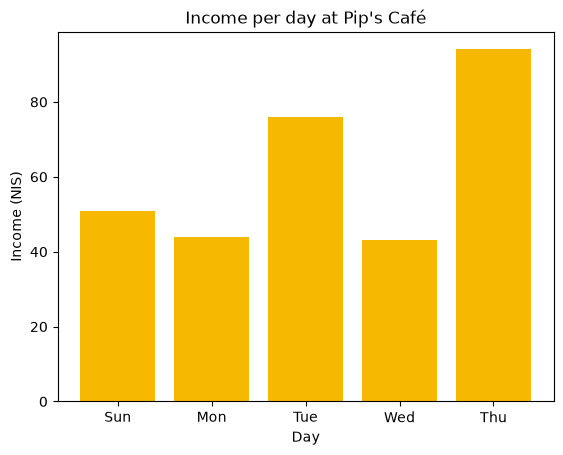

In [22]:
# 4. Plot
plt.bar(days, income, color="#F6B800")
plt.title("Income per day at Pip's Café")
plt.xlabel("Day")
plt.ylabel("Income (ILS)")
plt.show()

**5. Conclusion.** Thursday has the most orders (6) and the highest income, with Tuesday second.
**Pip should hire the extra barista on Thursday.**

Be honest about limits: this is **one** made-up week. A real decision needs several weeks of data.

💡 **Try it:** which day has the best average **rating**? Would you choose a different day for the barista if the goal were happier customers?

## 10. Bug Zoo: every bug from Part 4 🐛

| Bug | What you see | Fix |
|---|---|---|
| `np.array(...)` before `import numpy as np` | `NameError: name 'np' is not defined` | run the import cell first |
| `[12.5, 8] * 1.18` on a list | `TypeError: can't multiply sequence by non-int of type 'float'` | make it an array: `np.array([...]) * 1.18` |
| `pd.read_csv("coffee_order.csv")` | `FileNotFoundError` | exact file name, and upload it to Colab first |
| `df["Price"]` | `KeyError: 'Price'` | column names are exact: `df["price"]` |
| `plt.plot(x, y)` with different lengths | `ValueError: x and y must have same first dimension` | same number of x and y values |
| `plt.xlable("Day")` | `AttributeError` | spelling: `plt.xlabel` |
| `model.fit([14, 16, 18], y)` | `ValueError: Expected 2D array` | `[[14], [16], [18]]` |
| predicting far outside the data | no error, nonsense answer! | models have no common sense: stay in the range of the data |

**Your turn:** this cell should plot the income per day. Two bugs.

In [23]:
plt.bar(days, df["Price"])
plt.title("Income per day")
plt.show()

KeyError: 'Price'

<details><summary>Show the fixes</summary>

1. `KeyError: 'Price'`: the column is `"price"`.
2. Then `ValueError`: `days` has 5 values but `df["price"]` has 21 (one per order). Plot the per-day totals: `plt.bar(days, income)`.

</details>

## 11. Quick quiz: predict the output 🤔

1. `a = np.array([10, 20, 30])` then `print(a + 1)`
2. `print([10, 20, 30] + [1])`
3. `print(a[a > 15] - 10)`
4. `print(np.median([5, 1, 3, 100]))`
5. `t = np.array([[1, 2, 3], [4, 5, 6]])` then `print(t.shape, t[1, 0])`
6. `print(t.sum(axis=0))`
7. `df` has 21 rows. What does `len(df[df["price"] > 100])` give?
8. A regression learned from days of 14-33°C. Do you trust its prediction for -10°C?

<details><summary>Answers</summary>

1. `[11 21 31]`
2. `[10, 20, 30, 1]` (lists glue)
3. `[10 20]`
4. `4.0` (sorted: 1, 3, 5, 100, the middle two are 3 and 5)
5. `(2, 3) 4`
6. `[5 7 9]`
7. `0` (no order costs more than 100)
8. No: it is far outside the data. It might even predict a negative number of coffees.

</details>

## 12. Part 4 cheat sheet 📋

| I want to... | Code |
|---|---|
| open a toolbox | `import numpy as np`, `import pandas as pd`, `import matplotlib.pyplot as plt` |
| an array | `prices = np.array([12.5, 8, 9])` |
| math on all items | `prices * 1.18`, `prices + 1` |
| keep some items | `prices[prices > 10]` |
| statistics | `np.mean`, `np.median`, `np.percentile(x, 90)`, `np.max` |
| 2-D: size, one cell | `t.shape`, `t[row, col]` |
| down columns / across rows | `t.sum(axis=0)`, `t.mean(axis=1)` |
| load a table | `df = pd.read_csv("file.csv")` |
| look at it | `df.head()`, `df.describe()`, `len(df)` |
| one column | `df["price"]`, then `.sum()`, `.mean()`, `.median()` |
| filter rows | `df[df["drink"] == "Latte"]` |
| count values | `df["drink"].value_counts()` |
| line / bar / dots / histogram | `plt.plot`, `plt.bar`, `plt.scatter`, `plt.hist` |
| labels | `plt.title`, `plt.xlabel`, `plt.ylabel`, `label=` + `plt.legend()` |
| learn and predict | `model.fit(X, y)`, `model.predict([[30]])` |
| predict a number / a label / find groups | `LinearRegression`, `KNeighborsClassifier`, `KMeans` |
| use an object's ability | `thing.method(...)` |

## 13. The whole journey: one café, four parts

| Part | Pip's café could... | Thanks to |
|---|---|---|
| 1 Intro and Python Basics | print a sign, add up a bill, ask the customer, print a receipt | `print`, variables, `input`, f-strings, `if` |
| 2 Decisions and Loops | know the whole menu, apply discount rules, serve many customers | `elif`, `and`/`or`, lists, sets, loops |
| 3 Functions and Dictionaries | split the code into clean functions, keep a menu dictionary, report the day, catch bugs and check AI code | `def`, `return`, dictionaries, median by hand, debugging |
| 4 Data Science and AI | analyze a whole week, draw charts, predict sales, find customer groups | NumPy, Pandas, Matplotlib, scikit-learn |

Look back at the Part 1 counter program: a few `print` lines. You can now do all of this. 🎉

## What's next

**More Part 4 showcases**
* **Teach a computer to see** (`S4_digits_ai.ipynb`): a model that reads handwritten digits.
* **Will my savings reach the goal?** (`S4x_monte_carlo_money.ipynb`): thousands of possible futures for your money.

**Your final project.** Start from the project starter notebook (Lecture 10): pick a question you care about, find data, then load, explore, plot, conclude, just like section 9 above.